One of the machine learning models we will use to recreate the Hussain results is Ridge Regression. This behaves similiarly to Linear Regression but 'punishes' large coefficient values, to ensure a single coefficient doesn't dominate results. This is controlled by an alpha value, which is defined by the user and multiplies each coefficient to mark the 'level of punishment' a model receives

In [14]:
#Preparing the band gap data for machine learning.

import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

DATA_FILE = Path(
    "Data/Hussain_Replication/Aggregated_Configurations.csv"
)

df_filtered_5 = pd.read_csv(
    "Data/Hussain_Replication/Filtered_Experimental_Records.csv"
)

print("Records loaded:", len(df_filtered_5))

TEST_SIZE = 0.20
RANDOM_STATE = 42


df = pd.read_csv(DATA_FILE)

print("Original configurations:", len(df))


ion_columns = [
    'Perovskite_composition_a_ions',
    'Perovskite_composition_b_ions',
    'Perovskite_composition_c_ions'
]

coefficient_columns = [
    'Perovskite_composition_a_ions_coefficients',
    'Perovskite_composition_b_ions_coefficients',
    'Perovskite_composition_c_ions_coefficients'
]


# Define model inputs and prediction target
feature_columns = ion_columns + coefficient_columns
target_column = 'mean_band_gap'

# Prepare a fresh dataframe from the loaded CSV
df_model = df.copy()

# Ensure the target is numeric
df_model[target_column] = pd.to_numeric(
    df_model[target_column],
    errors='coerce'
)

# Remove rows missing any required input or target
df_model = df_model.dropna(
    subset=feature_columns + [target_column]
).copy()


#----------------------------------------------
#INVALID ION CONFIGURATIONS CHECK (Retroactively implemented)
def matching_ion_coefficients(row):

    for ion_col, coeff_col in zip(
        ion_columns,
        coefficient_columns
    ):
        ions = str(row[ion_col]).split(';')
        coefficients = str(row[coeff_col]).split(';')

        if len(ions) != len(coefficients):
            return False

    return True
# Find incorrectly formatted compositions
valid_compositions = df_model.apply(
    matching_ion_coefficients,
    axis=1
)
print("Invalid configurations:", (~valid_compositions).sum())

# Display problematic rows before removing them
display(df_model.loc[
    ~valid_compositions,
    feature_columns
])

# Keep only valid configurations
df_model = df_model.loc[valid_compositions].copy()

print("Configurations remaining:", len(df_model))
#----------------------------------------------



feature_columns = ion_columns + coefficient_columns

target_column = 'mean_band_gap'


X = df_model[feature_columns].copy()
y = df_model[target_column].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nExample input:")
display(X_train.head())

print("\nExample target:")
display(y_train.head())


Records loaded: 12672
Original configurations: 672
Invalid configurations: 4


,Perovskite_composition_a_ions,Perovskite_composition_b_ions,Perovskite_composition_c_ions,Perovskite_composition_a_ions_coefficients,Perovskite_composition_b_ions_coefficients,Perovskite_composition_c_ions_coefficients
35,Cs,Pb,Br; I,1,1,3
101,Cs; FA,Pb,I,1,1,3
178,Cs; FA; MA,Pb,Br; I,0.17; 0.83,1,0.51; 2.49
404,FA; MA,Pb,Br; I,1,1,0.45; 2.55


Configurations remaining: 668

Training samples: 534
Testing samples: 134

Example input:


,Perovskite_composition_a_ions,Perovskite_composition_b_ions,Perovskite_composition_c_ions,Perovskite_composition_a_ions_coefficients,Perovskite_composition_b_ions_coefficients,Perovskite_composition_c_ions_coefficients
238,FA,Pb,I,1,1,3
402,FA; MA,Pb,I,0.9; 0.1,1,3
606,MA,Pb,I,1,1,3
62,Cs; FA,Pb,Br; I,0.125; 0.875,1,0.375; 2.625
147,Cs; FA; MA,Pb,Br; I,0.05; 0.81; 0.14,1,0.4; 2.6



Example target:


238    1.480000
402    1.520000
606    1.600000
62     1.580909
147    1.610000
Name: mean_band_gap, dtype: float64

In [15]:
# Remove ion/coefficient count mismatches

df_filtered_5.to_csv(
    "Data/Hussain_Replication/Filtered_Experimental_Records.csv",
    index=False
)
def matching_ion_coefficients(row):
    for site in ['a', 'b', 'c']:
        ions = str(row[f'Perovskite_composition_{site}_ions']).split(';')
        coefficients = str(
            row[f'Perovskite_composition_{site}_ions_coefficients']
        ).split(';')

        if len(ions) != len(coefficients):
            return False

    return True

before = len(df_filtered_5)

df_filtered_5 = df_filtered_5[
    df_filtered_5.apply(matching_ion_coefficients, axis=1)
].copy()

print("Mismatched records removed:", before - len(df_filtered_5))

Mismatched records removed: 0


This uses the sklearn.model_selection package to randomly seperate data into 80% values for training the model and 20% for testing.
Training is done by providing the model the values we want to have an impact on predictions (for now only ion composition and coefficients), then showing it the result. It uses this to adjust coefficients of each inputs contribution. We can inspect these after training using "model.coef_".
For testing, the algorithm is not given the result, only the inputs and the answer it comes to is then checked against the known result. This allows us to qunatify the accuracy of the model produced.

So far only the raw data is prepared, but it is not yet ready for training/testing. The model can only learn from numbers, so ions must be vectorised and their coefficients must be made it numbers - particularly if they are compounds.


In [16]:
import numpy as np

allowed_ions = [
    'MA', 'FA', 'Cs',
    'Pb', 'Sn',
    'I', 'Br', 'Cl'
]

# Converts composition of ions to numbers.
def encode_composition(row):

    # Start with zero for every ion
    composition = {ion: 0.0 for ion in allowed_ions}

    # Examine A, B and C sites separately
    for ion_column, coefficient_column in zip(
        ion_columns,
        coefficient_columns
    ):

        # Split multi-ion strings into separate ions
        ions = [
            ion.strip()
            for ion in str(row[ion_column]).split(';')
        ]

        # Split coefficient values into individual numbers
        coefficients = [
            float(value.strip())
            for value in str(row[coefficient_column]).split(';')
        ]

        # Check each ion has a corresponding coefficient
        if len(ions) != len(coefficients):
            raise ValueError(
                f"Ion/coefficient mismatch at row {row.name}"
            )

        # Assign quantities to their respective ions
        for ion, coefficient in zip(ions, coefficients):

            if ion not in composition:
                raise ValueError(
                    f"Unexpected ion '{ion}' at row {row.name}"
                )

            composition[ion] += coefficient

    return pd.Series(composition)



# APPLY ENCODED COMPOSITIONS TO TRAINING AND TEST DATA
X_train_encoded = X_train.apply(
    encode_composition,
    axis=1
)

X_test_encoded = X_test.apply(
    encode_composition,
    axis=1
)

# Ensure identical column ordering
X_test_encoded = X_test_encoded[
    X_train_encoded.columns
]

print("Original training shape:", X_train.shape)
print("Encoded training shape:", X_train_encoded.shape)

print("\nOriginal input:")
display(X_train.head())

print("\nNumerical input:")
display(X_train_encoded.head())

print("\nMissing numerical values:")
print(X_train_encoded.isna().sum().sum())

print("\nEncoded columns:")
print(X_train_encoded.columns.tolist())


Original training shape: (534, 6)
Encoded training shape: (534, 8)

Original input:


,Perovskite_composition_a_ions,Perovskite_composition_b_ions,Perovskite_composition_c_ions,Perovskite_composition_a_ions_coefficients,Perovskite_composition_b_ions_coefficients,Perovskite_composition_c_ions_coefficients
238,FA,Pb,I,1,1,3
402,FA; MA,Pb,I,0.9; 0.1,1,3
606,MA,Pb,I,1,1,3
62,Cs; FA,Pb,Br; I,0.125; 0.875,1,0.375; 2.625
147,Cs; FA; MA,Pb,Br; I,0.05; 0.81; 0.14,1,0.4; 2.6



Numerical input:


,MA,FA,Cs,Pb,Sn,I,Br,Cl
238,0.00,1.000,0.000,1.0,0.0,3.000,0.000,0.0
402,0.10,0.900,0.000,1.0,0.0,3.000,0.000,0.0
606,1.00,0.000,0.000,1.0,0.0,3.000,0.000,0.0
62,0.00,0.875,0.125,1.0,0.0,2.625,0.375,0.0
147,0.14,0.810,0.050,1.0,0.0,2.600,0.400,0.0



Missing numerical values:
0

Encoded columns:
['MA', 'FA', 'Cs', 'Pb', 'Sn', 'I', 'Br', 'Cl']


Before continuing, my partner and I discussed the potential issue of including identical ionic compounds in both the training and testing dataset, which could artificially inflate the accuracy of the model. There is insufficient time to do this before the presentation but we will be investigating it after. A quick check was done to ensure there are enough unique compounds to use for training and testing, which is given below and comes to 351 unique combinations out of 677 unique experimental configurations, which is sufficient.

In [17]:
# Count unique chemical compositions, including stoichiometry

all_compositions = pd.concat([
    X_train_encoded,
    X_test_encoded
])

unique_compositions = all_compositions.drop_duplicates()

print("Total configurations:", len(all_compositions))
print("Unique chemical compositions:", len(unique_compositions))
print("Repeated compositions:", len(all_compositions) - len(unique_compositions))

Total configurations: 668
Unique chemical compositions: 344
Repeated compositions: 324


Continuing on to building the actual ridge regression:

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

ALPHA = 1.0


scaler = StandardScaler()

# Calculate scaling parameters from training data
X_train_scaled = scaler.fit_transform(X_train_encoded)

# Apply the same scaling to testing data
X_test_scaled = scaler.transform(X_test_encoded)

#Ridge Model creation and training
ridge_model = Ridge(alpha=ALPHA)

ridge_model.fit(X_train_scaled, y_train)

#Training predications
y_train_pred = ridge_model.predict(X_train_scaled)

#------------------------------------------------
#Evaluating training performance
train_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred)
)

train_mae = mean_absolute_error(
    y_train, y_train_pred
)

train_r2 = r2_score(
    y_train, y_train_pred
)
#------------------------------------------------

print("Initial alpha:", ALPHA)
print("Training RMSE:", round(train_rmse, 4), "eV")
print("Training MAE:", round(train_mae, 4), "eV")
print("Training R²:", round(train_r2, 4))

# ----------------------------------------------
# INSPECT LEARNED COEFFICIENTS
# ----------------------------------------------

coefficients = pd.DataFrame({
    'Ion': X_train_encoded.columns,
    'Ridge_weight': ridge_model.coef_
})

display(coefficients)


Initial alpha: 1.0
Training RMSE: 0.0969 eV
Training MAE: 0.0618 eV
Training R²: 0.8361


,Ion,Ridge_weight
0,MA,0.011364
1,FA,-0.005220
2,Cs,0.033798
3,Pb,0.002509
4,Sn,-0.085164
5,I,-0.010619
6,Br,0.175789
7,Cl,0.041255


Using the StandardScaler package was a suggestion from ChatGPT, and fills an oversite in the original plan to act with Ridge Regression on the training data immediately. 
The issue is that coefficients are generally unbalanced, due to the design of ABX perovskites:
1) A-Site coefficients ≈ 1
2) B-Site coefficients ≈ 1
3) X-Site coefficients ≈ 3
Which would cause ridge regression to punish X-Site influence on the model unfairly, so we need to normalise these three.
This is done by normalising using the mean and standard deviation of coefficient values across the training data (the same method as normalisation of a gaussian curve).
This same normalisation value is applied to the testing data. It is NOT recalculated on the testing data as this would influence model preperation; this is called Data Leakage (during pre-processing).

.fit() is the function that actually assigns coefficients to each ion and minimises the loss function ("penalty") discussed before.

The predictive results are promising at:
Training RMSE: 0.0969 eV
Training MAE: 0.06 eV
Training R²: 0.8371

This indicate neither under-fitting or over-fitting.

The next step is to find the most optimal alpha value, we will consider a low absolute RMSE the quantifier for a good alpha value for each version.
Initial tests were done over a range of 10^-3 to 10^3 as we were unsure what magnitude the alpha tends to have. This found 1,000 to be most effective, which was the highest possible value and seemed suspicious. To troubleshoot, we added 5-fold testing, which splits the full dataset into 4 training parts and 1 testing part. This is repeated 5 times, using each of the sections as a testing part to identifier any outliers.
This successfully identified an erroneous result in the dataset that had passed all previous filters, with a C-Site coefficient of 75, instead of an expected 1.75.
After correcting this manually, the test was done again and it resulted in a similiar issue with a different entry. So a filter stage was added to reject any coefficient sums that resulted in <2 or >6, allowing for some margin while removing clearly unphysical entries. This identified 27 entries in the filtered dataset to be removed.

In [19]:

import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, cross_val_score


# Alpha values to investigate
#Logspace generates numbers spaced evenly on a log scale, instead of linearly spaced values. This is useful for tuning, especially when the optimal value may vary over several orders of magnitude.
alpha_values = np.logspace(0, 2, 25) 

# Set up 5-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Store the results for each alpha
results = []

#Testing alpha values
for alpha in alpha_values:

    # Standardise features, then apply Ridge regression
    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha)
    )

    # Evaluate model using 5-fold cross-validation
    scores = cross_val_score(
        model,
        X_train_encoded,
        y_train,
        cv=cv,
        scoring='neg_root_mean_squared_error'
    )

    # Convert negative scoring values to positive RMSE
    rmse_values = -scores

    # Store the average and variability of RMSE
    results.append({
        'alpha': alpha,
        'mean_RMSE': rmse_values.mean(),
        'std_RMSE': rmse_values.std()
    })


#Results summary as a DataFrame for easier analysis.
alpha_results = pd.DataFrame(results)

# Find the alpha with the lowest average RMSE
best_result = alpha_results.loc[
    alpha_results['mean_RMSE'].idxmin()
]

best_alpha = best_result['alpha']

print("Best alpha:", best_alpha)
print(
    "Best cross-validation RMSE:",
    round(best_result['mean_RMSE'], 4),
    "eV"
)

print("\nAlpha comparison:")
display(alpha_results.round(4))


Best alpha: 21.544346900318832
Best cross-validation RMSE: 0.1051 eV

Alpha comparison:


,alpha,mean_RMSE,std_RMSE
0,1.0000,0.1065,0.0134
1,1.2115,0.1064,0.0134
2,1.4678,0.1063,0.0132
3,1.7783,0.1062,0.0131
4,2.1544,0.1061,0.0130
5,2.6102,0.1060,0.0128
6,3.1623,0.1059,0.0127
7,3.8312,0.1058,0.0125
8,4.6416,0.1057,0.0123
9,5.6234,0.1056,0.0120


The initial tests spanned 6 orders of magnitude to find Alpha = ~17 was the most accurate of the 25 tests, so the span was reduced to a span of 2 orders of magnitude to give Alpha = 21.5443469 as optimal. No further testing was needed for alpha, so the final training and testing was completed.

In [20]:

# PART 5: FINAL TRAINING AND TESTING

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import numpy as np
import pandas as pd

# Create the final model using the optimised alpha
final_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=best_alpha)
)

# Train using the entire training dataset
final_model.fit(X_train_encoded, y_train)

# Predict band gaps for the untouched testing dataset
y_test_pred = final_model.predict(X_test_encoded)

# Evaluate prediction accuracy
test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

print("Optimised alpha:", round(best_alpha, 4))
print("Testing MAE:", round(test_mae, 4), "eV")
print("Testing RMSE:", round(test_rmse, 4), "eV")
print("Testing R²:", round(test_r2, 4))

# Compare actual and predicted band gaps
prediction_results = pd.DataFrame({
    'Actual_band_gap': y_test,
    'Predicted_band_gap': y_test_pred
})

prediction_results['Absolute_error'] = (
    prediction_results['Actual_band_gap']
    - prediction_results['Predicted_band_gap']
).abs()

display(prediction_results.head(10))


Optimised alpha: 21.5443
Testing MAE: 0.0683 eV
Testing RMSE: 0.1022 eV
Testing R²: 0.8309


,Actual_band_gap,Predicted_band_gap,Absolute_error
364,1.627714,1.633722,0.006008
160,1.630000,1.641668,0.011668
481,1.690000,1.726362,0.036362
521,1.595162,1.553619,0.041543
278,1.407500,1.175642,0.231858
365,1.600000,1.633722,0.033722
313,1.510000,1.559937,0.049937
202,1.633000,1.570525,0.062475
525,1.600000,1.553619,0.046381
91,1.320000,1.372649,0.052649


In [21]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def plot_actual_vs_predicted(y_true, y_pred, title):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    plt.figure(figsize=(7, 7))
    plt.scatter(y_true, y_pred, alpha=0.7)

    # Ideal line y = x
    min_val = min(np.min(y_true), np.min(y_pred))
    max_val = max(np.max(y_true), np.max(y_pred))
    plt.plot([min_val, max_val], [min_val, max_val], '--')

    plt.xlabel("Actual value")
    plt.ylabel("Predicted value")
    plt.title(title)

    text = f"MAE = {mae:.4f}\nRMSE = {rmse:.4f}\nR² = {r2:.4f}"
    plt.text(
        0.05, 0.95, text,
        transform=plt.gca().transAxes,
        verticalalignment='top',
        bbox=dict(facecolor='white', alpha=0.8)
    )

    plt.show()

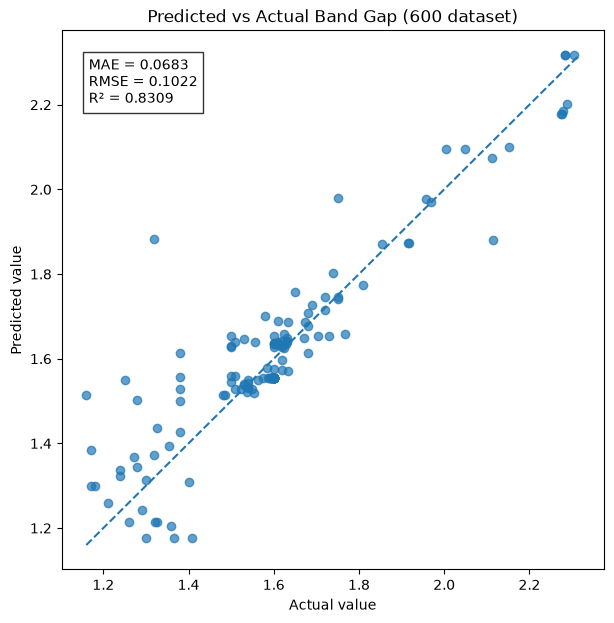

In [22]:
plot_actual_vs_predicted(
    y_test,
    y_test_pred,
    "Predicted vs Actual Band Gap (600 dataset)"
)

Next we wanted to investigate how effective the model trained on the aggregated 600 values was at predicting the non-aggregated dataset (12,000 entries), seeing as the bias of training on the primarily MABrI would be reduced from training on the aggregated values.

In [ ]:


# MODEL 2: TRAIN ON 600, PREDICT ON 12,000

from pathlib import Path

experimental_file = Path(
    "Data/Hussain_Replication/Filtered_Experimental_Records.csv"
)

df_experimental = pd.read_csv(experimental_file)

print("CSV path:", experimental_file.resolve())

print("\nProblematic record:")
display(
    df_experimental.loc[
        [11929],
        ion_columns + coefficient_columns
    ]
)

experimental_target = "Perovskite_band_gap"

# Aggregated training dataset
X_600 = df_model.apply(encode_composition, axis=1)
y_600 = df_model[target_column]

# Experimental prediction dataset
X_12000 = df_experimental.apply(encode_composition, axis=1)
y_12000 = pd.to_numeric(
    df_experimental[experimental_target],
    errors="coerce"
)

# Use the same feature order
X_600 = X_600[X_train_encoded.columns]
X_12000 = X_12000[X_train_encoded.columns]

model_600_to_12000 = make_pipeline(
    StandardScaler(),
    Ridge(alpha=best_alpha)
)

model_600_to_12000.fit(X_600, y_600)

y_12000_pred = model_600_to_12000.predict(X_12000)

print("\nMODEL 2: AGGREGATED TO EXPERIMENTAL")
print("Training samples:", len(X_600))
print("Prediction samples:", len(X_12000))
print("Best alpha:", round(best_alpha, 4))

print("MAE:", round(
    mean_absolute_error(y_12000, y_12000_pred), 4
), "eV")

print("RMSE:", round(
    np.sqrt(mean_squared_error(y_12000, y_12000_pred)), 4
), "eV")

print("R²:", round(
    r2_score(y_12000, y_12000_pred), 4
))


NameError: name 'experimental_file' is not defined

In [ ]:

# MODEL 3: BAND GAP - EXPERIMENTAL DATASET (80/20 SPLIT)

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


file_12000 = Path("Data/Hussain_Replication/Filtered_Experimental_Records.csv")

data_12000 = pd.read_csv(file_12000)

ion_cols = [
    "Perovskite_composition_a_ions",
    "Perovskite_composition_b_ions",
    "Perovskite_composition_c_ions"
]

coeff_cols = [
    "Perovskite_composition_a_ions_coefficients",
    "Perovskite_composition_b_ions_coefficients",
    "Perovskite_composition_c_ions_coefficients"
]

allowed_ions = ["MA", "FA", "Cs", "Pb", "Sn", "I", "Br", "Cl"]
target = "Perovskite_band_gap"



def encode_valid_composition(row):
    composition = {ion: 0.0 for ion in allowed_ions}
    total = 0.0

    for ion_col, coeff_col in zip(ion_cols, coeff_cols):
        ions = [x.strip() for x in str(row[ion_col]).split(";")]

        try:
            coefficients = [
                float(x.strip())
                for x in str(row[coeff_col]).split(";")
            ]
        except (ValueError, TypeError):
            return None

        if len(ions) != len(coefficients):
            return None

        if any(ion not in composition for ion in ions):
            return None

        if not all(np.isfinite(x) and x > 0 for x in coefficients):
            return None

        for ion, coefficient in zip(ions, coefficients):
            composition[ion] += coefficient
            total += coefficient

    # Apply the same physical-plausibility rule as Filter 5
    if not 2 <= total <= 6:
        return None

    return composition


data_12000[target] = pd.to_numeric(data_12000[target], errors="coerce")

encoded_rows = []
valid_indices = []

for index, row in data_12000.iterrows():
    encoded = encode_valid_composition(row)

    if encoded is not None and pd.notna(row[target]):
        encoded_rows.append(encoded)
        valid_indices.append(index)

X_12k = pd.DataFrame(
    encoded_rows,
    index=valid_indices,
    columns=allowed_ions
)

y_12k = data_12000.loc[valid_indices, target]

print("Usable records:", len(X_12k))
print("Records excluded:", len(data_12000) - len(X_12k))



# 3. TRAIN / TEST SPLIT
X_train_12k, X_test_12k, y_train_12k, y_test_12k = train_test_split(
    X_12k,
    y_12k,
    test_size=0.20,
    random_state=42
)


# 4. OPTIMISE ALPHA ON TRAINING DATA ONLY

alpha_values_12k = np.logspace(1, 4, 25)

cv_12k = KFold(n_splits=5, shuffle=True, random_state=42)

alpha_scores_12k = []

for alpha in alpha_values_12k:
    pipeline = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha)
    )

    rmse_scores = -cross_val_score(
        pipeline,
        X_train_12k,
        y_train_12k,
        cv=cv_12k,
        scoring="neg_root_mean_squared_error"
    )

    alpha_scores_12k.append(rmse_scores.mean())

best_alpha_12k = alpha_values_12k[np.argmin(alpha_scores_12k)]
best_cv_rmse_12k = min(alpha_scores_12k)



# 5. FINAL TRAINING AND TESTING=
model_12k = make_pipeline(
    StandardScaler(),
    Ridge(alpha=best_alpha_12k)
)

model_12k.fit(X_train_12k, y_train_12k)

y_pred_12k = model_12k.predict(X_test_12k)

mae_12k = mean_absolute_error(y_test_12k, y_pred_12k)
rmse_12k = np.sqrt(mean_squared_error(y_test_12k, y_pred_12k))
r2_12k = r2_score(y_test_12k, y_pred_12k)

print("\nMODEL 3: BAND GAP - 12,000 DATASET")
print("----------------------------------------")
print("Training samples:", len(X_train_12k))
print("Testing samples:", len(X_test_12k))
print("Best alpha:", round(best_alpha_12k, 4))
print("Cross-validation RMSE:", round(best_cv_rmse_12k, 4), "eV")
print("Test MAE:", round(mae_12k, 4), "eV")
print("Test RMSE:", round(rmse_12k, 4), "eV")
print("Test R²:", round(r2_12k, 4))


Usable records: 12672
Records excluded: 0

MODEL 3: BAND GAP - 12,000 DATASET
----------------------------------------
Training samples: 10137
Testing samples: 2535
Best alpha: 100.0
Cross-validation RMSE: 0.0422 eV
Test MAE: 0.0192 eV
Test RMSE: 0.0462 eV
Test R²: 0.8458


In [ ]:
# MODEL 4: PCE - AGGREGATED DATASET (80/20 SPLIT)
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


file_600 = Path("Data/Hussain_Replication/Aggregated_Configurations.csv")

data_pce = pd.read_csv(file_600)

pce_ion_cols = [
    "Perovskite_composition_a_ions",
    "Perovskite_composition_b_ions",
    "Perovskite_composition_c_ions"
]

pce_coeff_cols = [
    "Perovskite_composition_a_ions_coefficients",
    "Perovskite_composition_b_ions_coefficients",
    "Perovskite_composition_c_ions_coefficients"
]

pce_allowed_ions = ["MA", "FA", "Cs", "Pb", "Sn", "I", "Br", "Cl"]
pce_target = "mean_PCE"



# 2. VALIDATE AND ENCODE COMPOSITIONS
def encode_pce_composition(row):
    composition = {ion: 0.0 for ion in pce_allowed_ions}
    total = 0.0

    for ion_col, coeff_col in zip(pce_ion_cols, pce_coeff_cols):
        ions = [x.strip() for x in str(row[ion_col]).split(";")]

        try:
            coefficients = [
                float(x.strip())
                for x in str(row[coeff_col]).split(";")
            ]
        except (ValueError, TypeError):
            return None

        if len(ions) != len(coefficients):
            return None

        if any(ion not in composition for ion in ions):
            return None

        if not all(np.isfinite(x) and x > 0 for x in coefficients):
            return None

        for ion, coefficient in zip(ions, coefficients):
            composition[ion] += coefficient
            total += coefficient

    if not 2 <= total <= 6:
        return None

    return composition


data_pce[pce_target] = pd.to_numeric(
    data_pce[pce_target],
    errors="coerce"
)

encoded_pce_rows = []
valid_pce_indices = []

for index, row in data_pce.iterrows():
    encoded = encode_pce_composition(row)

    if encoded is not None and pd.notna(row[pce_target]):
        encoded_pce_rows.append(encoded)
        valid_pce_indices.append(index)

X_pce = pd.DataFrame(
    encoded_pce_rows,
    index=valid_pce_indices,
    columns=pce_allowed_ions
)

y_pce = data_pce.loc[valid_pce_indices, pce_target]

print("Usable configurations:", len(X_pce))
print("Configurations excluded:", len(data_pce) - len(X_pce))



# 3. TRAIN / TEST SPLIT
X_train_pce, X_test_pce, y_train_pce, y_test_pce = train_test_split(
    X_pce,
    y_pce,
    test_size=0.20,
    random_state=42
)

alpha_values_pce = np.logspace(0, 3, 25)

cv_pce = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

alpha_scores_pce = []

for alpha in alpha_values_pce:

    pipeline = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha)
    )

    rmse_scores = -cross_val_score(
        pipeline,
        X_train_pce,
        y_train_pce,
        cv=cv_pce,
        scoring="neg_root_mean_squared_error"
    )

    alpha_scores_pce.append(rmse_scores.mean())

best_alpha_pce = alpha_values_pce[
    np.argmin(alpha_scores_pce)
]

best_cv_rmse_pce = min(alpha_scores_pce)


model_pce = make_pipeline(
    StandardScaler(),
    Ridge(alpha=best_alpha_pce)
)

model_pce.fit(X_train_pce, y_train_pce)

y_pred_pce = model_pce.predict(X_test_pce)

mae_pce = mean_absolute_error(y_test_pce, y_pred_pce)
rmse_pce = np.sqrt(mean_squared_error(y_test_pce, y_pred_pce))
r2_pce = r2_score(y_test_pce, y_pred_pce)

print("\nMODEL 4: PCE - AGGREGATED DATASET")
print("----------------------------------------")
print("Training samples:", len(X_train_pce))
print("Testing samples:", len(X_test_pce))
print("Best alpha:", round(best_alpha_pce, 4))
print("Cross-validation RMSE:", round(best_cv_rmse_pce, 4), "percentage points")
print("Test MAE:", round(mae_pce, 4), "percentage points")
print("Test RMSE:", round(rmse_pce, 4), "percentage points")
print("Test R²:", round(r2_pce, 4))


Usable configurations: 668
Configurations excluded: 4

MODEL 4: PCE - AGGREGATED DATASET
----------------------------------------
Training samples: 534
Testing samples: 134
Best alpha: 31.6228
Cross-validation RMSE: 4.6236 percentage points
Test MAE: 3.2083 percentage points
Test RMSE: 3.8588 percentage points
Test R²: 0.4535


In [ ]:
# MODEL COMPARISON DATABASE
import pandas as pd
from pathlib import Path

# File to store all model results
results_file = Path("Data/Model_Comparison_Results.csv")

results_file.parent.mkdir(parents=True, exist_ok=True)

# Define columns for comparison
columns = [
    "Researcher",
    "Model",
    "Target",
    "Training_Dataset",
    "Testing_Dataset",
    "Training_Samples",
    "Testing_Samples",
    "Features",
    "Best_Alpha",
    "CV_RMSE",
    "Test_RMSE",
    "Test_R2"
]

# Load existing results or create a new database
if results_file.exists():
    model_results = pd.read_csv(results_file)
else:
    model_results = pd.DataFrame(columns=columns)

print("Models currently recorded:", len(model_results))
display(model_results)


Models currently recorded: 0


,Researcher,Model,Target,Training_Dataset,Testing_Dataset,Training_Samples,Testing_Samples,Features,Best_Alpha,CV_RMSE,Test_RMSE,Test_R2


In [ ]:
def add_model(
    researcher,
    model,
    target,
    training_dataset,
    testing_dataset,
    training_samples,
    testing_samples,
    features,
    best_alpha,
    cv_rmse,
    test_rmse,
    test_r2
):

    global model_results

    new_result = pd.DataFrame([{
        "Researcher": researcher,
        "Model": model,
        "Target": target,
        "Training_Dataset": training_dataset,
        "Testing_Dataset": testing_dataset,
        "Training_Samples": training_samples,
        "Testing_Samples": testing_samples,
        "Features": features,
        "Best_Alpha": best_alpha,
        "CV_RMSE": cv_rmse,
        "Test_RMSE": test_rmse,
        "Test_R2": test_r2
    }])

    model_results = pd.concat(
        [model_results, new_result],
        ignore_index=True
    )

    model_results.to_csv(results_file, index=False)

    print("Model saved successfully.")
    display(model_results.tail())


# Remove the # symbols once you have the results.

# add_model(
#     researcher="Me",
#     model="Ridge Regression",
#     target="Band Gap",
#     training_dataset="600 Aggregated",
#     testing_dataset="600 Holdout (20%)",
#     training_samples=541,
#     testing_samples=136,
#     features="8 ion coefficients",
#     best_alpha=17.7828,
#     cv_rmse=None,
#     test_rmse=None,
#     test_r2=None
# )


In [ ]:

comparison = model_results[
    [
        "Researcher",
        "Model",
        "Target",
        "Training_Dataset",
        "Testing_Dataset",
        "Test_RMSE",
        "Test_R2"
    ]
].copy()

# Compare models predicting the same target separately
comparison = comparison.sort_values(
    by=["Target", "Test_RMSE"],
    na_position="last"
)

display(comparison)


,Researcher,Model,Target,Training_Dataset,Testing_Dataset,Test_RMSE,Test_R2


In [ ]:
import pandas as pd
from pathlib import Path

results_file = Path("Data/Model_Comparison_Results.csv")
results_file.parent.mkdir(parents=True, exist_ok=True)

def save_results(rows):

    # Load existing results or start a new database
    if results_file.exists():
        database = pd.read_csv(results_file)
    else:
        database = pd.DataFrame()

    new_results = pd.DataFrame(rows)

    # Replace previous results for the same experiment
    if not database.empty:
        database = database[
            ~database["Run_ID"].isin(new_results["Run_ID"])
        ]

    # Combine and save
    database = pd.concat(
        [database, new_results],
        ignore_index=True
    )

    database.to_csv(results_file, index=False)

    print("Results saved to:", results_file.resolve())
    display(database)


In [ ]:

save_results([
    {
        "Run_ID": "Ridge_600_Bandgap",
        "Researcher": "Joshua",
        "Model": "Ridge",
        "Target": "Band gap",
        "Training_Dataset": "600 aggregated",
        "Testing_Dataset": "600 holdout 20%",
        "Training_Samples": len(X_train_encoded),
        "Testing_Samples": len(X_test_encoded),
        "Hyperparameter": f"alpha={best_alpha:.4f}",
        "Test_RMSE": test_rmse,
        "Test_R2": test_r2
    },
    {
        "Run_ID": "Ridge_600_to_12000",
        "Researcher": "Joshua",
        "Model": "Ridge",
        "Target": "Band gap",
        "Training_Dataset": "600 aggregated",
        "Testing_Dataset": "12000 experimental",
        "Training_Samples": len(X_600),
        "Testing_Samples": len(X_12000),
        "Hyperparameter": f"alpha={best_alpha:.4f}",
        "Test_RMSE": np.sqrt(mean_squared_error(y_12000, y_12000_pred)),
        "Test_R2": r2_score(y_12000, y_12000_pred)
    },
    {
        "Run_ID": "Ridge_12000_Bandgap",
        "Researcher": "Joshua",
        "Model": "Ridge",
        "Target": "Band gap",
        "Training_Dataset": "12000 experimental",
        "Testing_Dataset": "12000 holdout 20%",
        "Training_Samples": len(X_train_12k),
        "Testing_Samples": len(X_test_12k),
        "Hyperparameter": f"alpha={best_alpha_12k:.4f}",
        "Test_RMSE": rmse_12k,
        "Test_R2": r2_12k
    },
    {
        "Run_ID": "Ridge_600_PCE",
        "Researcher": "Joshua",
        "Model": "Ridge",
        "Target": "PCE",
        "Training_Dataset": "600 aggregated",
        "Testing_Dataset": "600 holdout 20%",
        "Training_Samples": len(X_train_pce),
        "Testing_Samples": len(X_test_pce),
        "Hyperparameter": f"alpha={best_alpha_pce:.4f}",
        "Test_RMSE": rmse_pce,
        "Test_R2": r2_pce
    }
])


NameError: name 'X_600' is not defined